# UFC Portfolio Analysis: How Do Finishes Differ Across Weight Classes?

**Research question:** How do UFC fight outcomes differ across weight classes, and have knockout, submission, and decision rates changed from 2013 to 2025?

**Dataset:** For this project, I used Nicholas Bair's UFC Data v0.1.1, which includes information from UFCStats and MMA Decisions.

**Source:** https://github.com/nlbair/ufc-data

**License:** Creative Commons Attribution 4.0 (CC BY 4.0).

This is an independent analysis and is not affiliated with the UFC.

In [18]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from IPython.display import display

ROOT = Path.cwd()
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
DATA_URL = "https://raw.githubusercontent.com/nlbair/ufc-data/main/data/ufc_all_fights_wide.csv"
REPO_URL = "https://github.com/leonhong2007/ufc-finish-analysis"
plt.rcParams.update({"figure.dpi": 125, "font.size": 11})

## 1. Load data and check its structure
I loaded the UFC dataset using Python and checked its structure, including the number of rows, columns, and missing values. Each row represents one fight, and I focused on the information relevant to my analysis.

In [19]:
wanted = ["fight_id", "event_date", "bout_text", "method", "is_decision", "winner", "finish_type"]
df = pd.read_csv(DATA_URL, usecols=lambda c: c in wanted, low_memory=False)
print("Original rows:", len(df))
print("Available columns:", df.columns.tolist())
display(df.head(5))
print("Missing values before cleaning:\n", df.isna().sum())

Original rows: 6743
Available columns: ['fight_id', 'event_date', 'bout_text', 'method', 'winner', 'is_decision', 'finish_type']


,fight_id,event_date,bout_text,method,winner,is_decision,finish_type
0,7db1a3dac7e343e7,2026-10-10,Middleweight Bout,Submission,1.0,False,submission
1,295339c08c80a3cf,2026-10-10,Lightweight Bout,Decision - Unanimous,2.0,True,decision
2,4f0f783503d5b5c4,2026-10-10,Women's Strawweight Bout,Decision - Unanimous,1.0,True,decision
3,e8710a6236db464e,2026-10-10,Featherweight Bout,KO/TKO,1.0,False,ko_tko
4,c56bbc28d155f846,2026-10-10,Bantamweight Bout,KO/TKO,2.0,False,ko_tko


Missing values before cleaning:
 fight_id        0
event_date      0
bout_text       0
method          0
winner         75
is_decision     0
finish_type     0
dtype: int64


## 2. Clean and document decisions

Before analyzing the UFC fights, I cleaned the dataset to make sure the results were accurate and consistent.

- I limited the data to fights from **2013–2025** so I could compare complete years.
- I removed duplicate fight IDs and records with invalid dates or weight classes.
- I excluded no contests, draws, overturned results, and unknown finishing methods because they didn't fit my three main outcome categories.
- I standardized weight-class names and finishing methods to keep everything consistent.
- I only included weight classes with **at least 75 classified fights** to avoid drawing conclusions from very small samples.

The cleaning audit below shows how many records were removed during each step.

In [20]:
audit = []
def log(step, before, after):
    audit.append({"step": step, "rows_before": before, "rows_after": after, "removed": before - after})

x = df.copy()
before = len(x); x = x.drop_duplicates(subset="fight_id"); log("Duplicate fight IDs", before, len(x))
before = len(x); x["event_date"] = pd.to_datetime(x["event_date"], errors="coerce")
x = x[x["event_date"].dt.year.between(2013, 2025)].copy(); log("Invalid dates or outside 2013–2025", before, len(x))
x["year"] = x["event_date"].dt.year.astype(int)

# Human-readable division field from the fight description, e.g. 'Lightweight Bout'.
x["division"] = x["bout_text"].astype('string').str.replace(r"\s+Bout$", "", regex=True).str.strip()
# Avoid treating special 'Catch Weight' bouts as a weight class.
before = len(x)
x = x[x["division"].notna() & (x["division"] != "") & (~x["division"].str.contains("Catch Weight|Open Weight", case=False, na=False))].copy()
log("Missing / nonstandard division", before, len(x))

m = x["method"].fillna("").astype(str).str.upper()
x["finish_category"] = np.select(
    [m.str.contains(r"KO|TKO", regex=True), m.str.contains(r"SUBMISSION|\bSUB\b", regex=True), m.str.contains("DECISION")],
    ["KO/TKO", "Submission", "Decision"], default="Other")
# Many datasets use 'Decision - Unanimous', 'Decision - Split', etc.
if "is_decision" in x:
    decision_flag = x["is_decision"].astype(str).str.lower().eq('true')
    x.loc[decision_flag & (x["finish_category"] == "Other"), "finish_category"] = "Decision"
# Never count a draw, NC or overturned result as a standard win.
if "winner" in x:
    won = x["winner"].notna() & (x["winner"].astype(str).str.strip() != "")
else:
    won = pd.Series(True, index=x.index)
before = len(x)
x = x[x["finish_category"].ne("Other") & won].copy()
log("Draw/NC/overturned/missing or unclassified outcome", before, len(x))
assert x["fight_id"].is_unique
assert x["finish_category"].isin(["KO/TKO", "Submission", "Decision"]).all()
audit_df = pd.DataFrame(audit)
display(audit_df)
print("Final analytical fights:", len(x))
print("Division examples:", x["division"].value_counts().head(15).to_dict())

,step,rows_before,rows_after,removed
0,Duplicate fight IDs,6743,6743,0
1,Invalid dates or outside 2013–2025,6743,6302,441
2,Missing / nonstandard division,6302,6235,67
3,Draw/NC/overturned/missing or unclassified out...,6235,6147,88


Final analytical fights: 6147
Division examples: {'Lightweight': 932, 'Welterweight': 879, 'Featherweight': 696, 'Middleweight': 690, 'Bantamweight': 629, 'Light Heavyweight': 430, 'Heavyweight': 428, 'Flyweight': 353, "Women's Strawweight": 333, "Women's Flyweight": 251, "Women's Bantamweight": 214, 'UFC Light Heavyweight Title': 24, 'UFC Flyweight Title': 24, 'UFC Welterweight Title': 23, 'UFC Bantamweight Title': 22}


## 3. Descriptive statistics and three visualizations

All plotted percentages use the number of **classified bouts** in the applicable group as the denominator. They do not measure the causal effect of fighter size or ability.

Overall classified fights: 6147


,fights,share_percent
finish_category,,
KO/TKO,1967,32.0
Submission,1095,17.8
Decision,3085,50.2


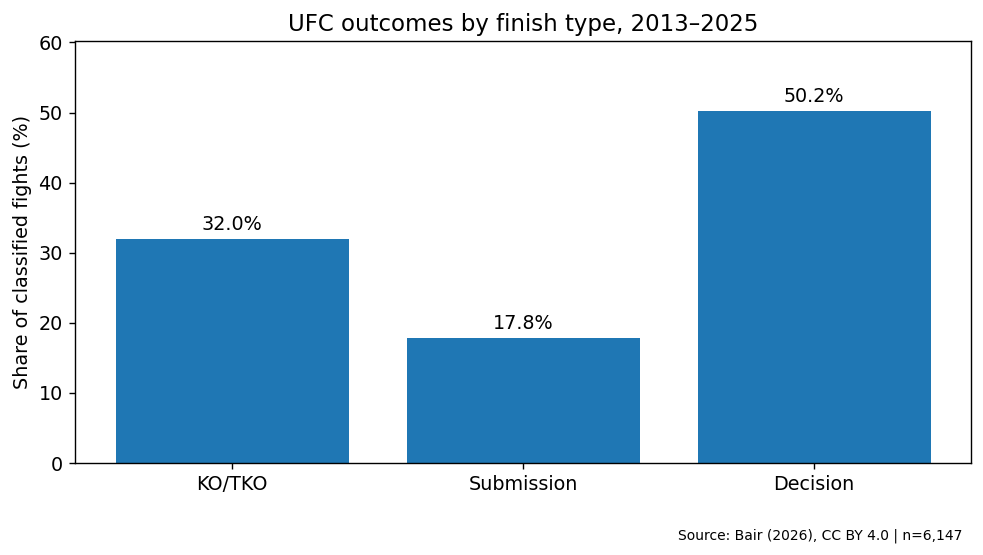

In [21]:
order = ["KO/TKO", "Submission", "Decision"]
overall = x["finish_category"].value_counts().reindex(order, fill_value=0)
shares = overall / overall.sum() * 100
print("Overall classified fights:", int(overall.sum()))
display(pd.DataFrame({"fights": overall, "share_percent": shares.round(1)}))
fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(order, shares.values)
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set(ylabel="Share of classified fights (%)", title="UFC outcomes by finish type, 2013–2025", ylim=(0, max(shares)*1.2))
ax.text(0.99, -0.18, f"Source: Bair (2026), CC BY 4.0 | n={len(x):,}", transform=ax.transAxes, ha="right", fontsize=8)
fig.tight_layout();fig.savefig(CHARTS/"01_overall_finish_types.png", dpi=180, bbox_inches="tight");plt.show()

Weight classes meeting 75-fight threshold: 11


finish_category,KO/TKO,Submission,Decision,total
division,,,,
Lightweight,299,170,463,932
Welterweight,301,147,431,879
Featherweight,204,118,374,696
Middleweight,269,128,293,690
Bantamweight,164,124,341,629
Light Heavyweight,198,71,161,430
Heavyweight,211,53,164,428
Flyweight,85,72,196,353
Women's Strawweight,41,67,225,333


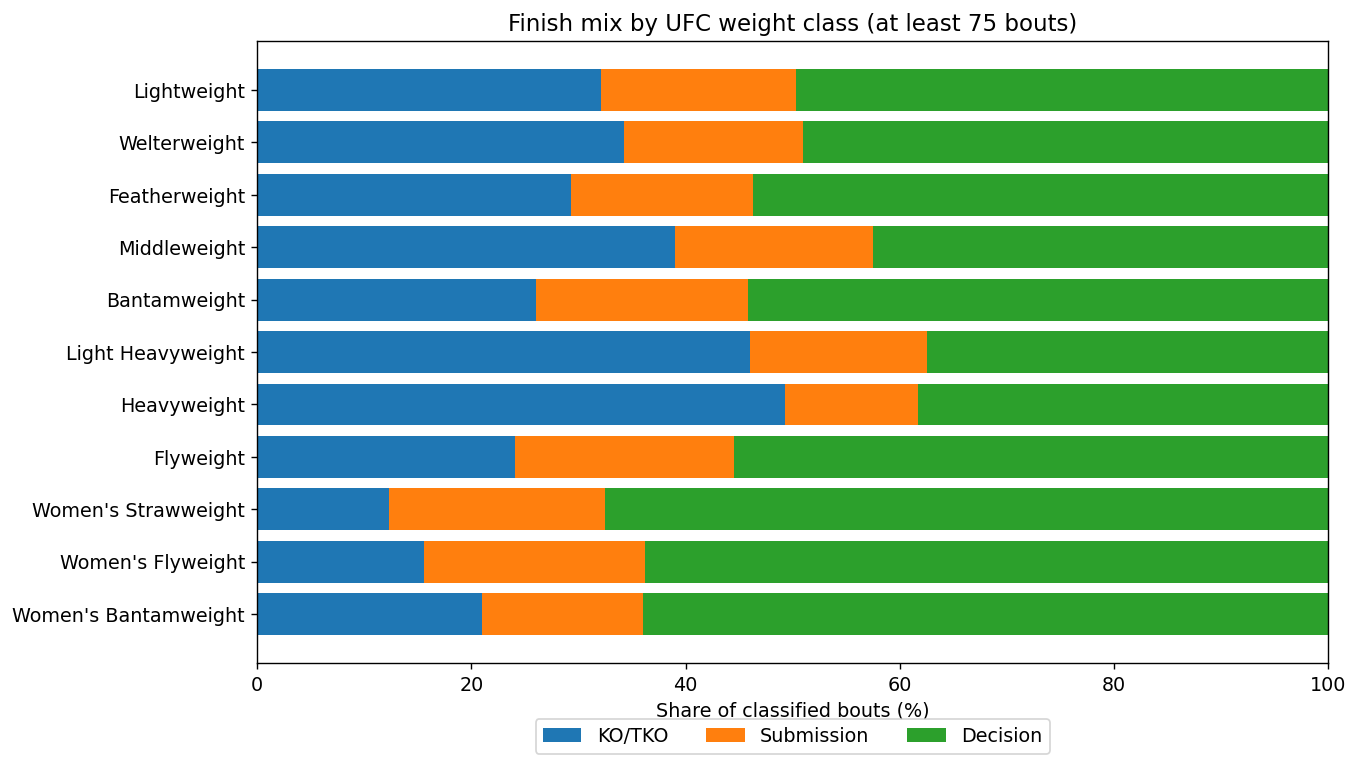

Chi-square association test: chi2=255.95, df=20, p=7.192e-43, Cramer's V=0.148
Interpretation: a test of association, not evidence that weight class causes a finish type.


In [22]:
counts_by_div = x["division"].value_counts()
keep_div = counts_by_div[counts_by_div >= 75].index
y = x[x["division"].isin(keep_div)].copy()
ct = pd.crosstab(y["division"], y["finish_category"]).reindex(columns=order, fill_value=0)
ct = ct.loc[ct.sum(axis=1).sort_values(ascending=False).index]
pct = ct.div(ct.sum(axis=1), axis=0)*100
print("Weight classes meeting 75-fight threshold:", len(ct))
display(ct.assign(total=ct.sum(axis=1)))
fig,ax=plt.subplots(figsize=(11, max(5, 0.43*len(ct)+1.5)))
left = np.zeros(len(ct))
for category in order:
    vals = pct[category].to_numpy()
    ax.barh(ct.index, vals, left=left, label=category)
    left += vals
ax.invert_yaxis();ax.set(xlabel="Share of classified bouts (%)", title="Finish mix by UFC weight class (at least 75 bouts)", xlim=(0,100))
ax.legend(loc="lower center", bbox_to_anchor=(0.5,-0.16), ncol=3)
fig.tight_layout();fig.savefig(CHARTS/"02_weight_class_finish_mix.png",dpi=180,bbox_inches="tight");plt.show()

chi2, p, dof, expected = chi2_contingency(ct)
n=ct.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n*min(ct.shape[0]-1,ct.shape[1]-1)))
print(f"Chi-square association test: chi2={chi2:.2f}, df={dof}, p={p:.4g}, Cramer's V={cramers_v:.3f}")
print("Interpretation: a test of association, not evidence that weight class causes a finish type.")

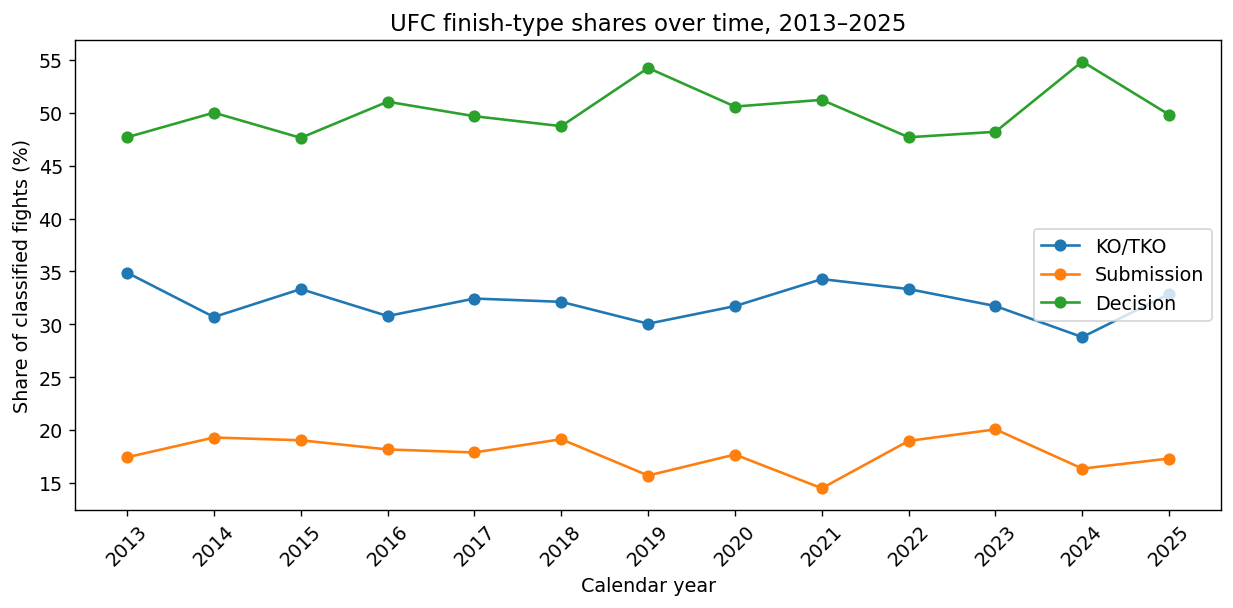

finish_category,KO/TKO,Submission,Decision
year,,,
2013,34.9,17.4,47.7
2014,30.7,19.3,50.0
2015,33.3,19.0,47.6
2016,30.8,18.2,51.0
2017,32.4,17.9,49.7
2018,32.1,19.1,48.7
2019,30.1,15.7,54.2
2020,31.7,17.7,50.6
2021,34.3,14.5,51.2


In [23]:
year_counts = pd.crosstab(x["year"], x["finish_category"]).reindex(columns=order, fill_value=0)
year_pct = year_counts.div(year_counts.sum(axis=1), axis=0)*100
fig,ax=plt.subplots(figsize=(10,5))
for category in order:
    ax.plot(year_pct.index, year_pct[category], marker="o", label=category)
ax.set(xlabel="Calendar year", ylabel="Share of classified fights (%)", title="UFC finish-type shares over time, 2013–2025")
ax.set_xticks(year_pct.index);ax.tick_params(axis='x',rotation=45);ax.legend()
fig.tight_layout();fig.savefig(CHARTS/"03_finish_trends_by_year.png",dpi=180,bbox_inches="tight");plt.show()
display(year_pct.round(1))

## 4. Interpretation, limitations, and reproducibility

I used Python to analyze UFC finishing methods and summarize the results. I also created visualizations to compare finishing rates across weight classes and over time.

**Limitations:** This is observational, bout-level data; fighter skill, stylistic matchups, fight length, rule changes, and matchmaker decisions could influence finish outcomes. Weight-class sample sizes differ. Data are independently assembled from several sources. This analysis describes completed bouts; it is **not** a pre-fight betting or prediction model.

In [24]:
top_ko = pct["KO/TKO"].idxmax(); low_ko = pct["KO/TKO"].idxmin()
first_year,last_year=int(year_pct.index.min()),int(year_pct.index.max())
findings = [
    f"Of {len(x):,} classified UFC fights (2013–2025), {shares['KO/TKO']:.1f}% ended by KO/TKO, {shares['Submission']:.1f}% by submission and {shares['Decision']:.1f}% by decision.",
    f"Among divisions with at least 75 fights, {top_ko} had the highest KO/TKO share ({pct.loc[top_ko,'KO/TKO']:.1f}%), while {low_ko} had the lowest ({pct.loc[low_ko,'KO/TKO']:.1f}%).",
    f"KO/TKO share was {year_pct.loc[first_year,'KO/TKO']:.1f}% in {first_year} and {year_pct.loc[last_year,'KO/TKO']:.1f}% in {last_year}; this describes an observed pattern, not a causal trend.",
    f"The weight-class-versus-finish association test gave chi-square={chi2:.2f} (df={dof}, p={p:.3g}) and Cramer's V={cramers_v:.3f}."
]
for i,s in enumerate(findings,1): print(f"Finding {i}: {s}")

steps = "\n".join(f"- {row.step}: {row.rows_before:,} -> {row.rows_after:,} (removed {row.removed:,})" for row in audit_df.itertuples())
findings_md = "\n".join(f"{i}. {s}" for i,s in enumerate(findings,1))
readme = f"""# UFC Fight Finishes: Weight Classes and Trends (2013–2025)

## Question / why it matters
Do UFC fight outcomes (KO/TKO, submission, decision) differ by weight class, and how has that mix shifted over time? I am interested in MMA strategy and whether different weight classes tend to finish fights in different ways.

## Data and licensing
- **Dataset:** Nicholas Bair, *UFC Data: scorecards, round statistics, and betting odds, 2013 to 2026*, v0.1.1 (2026), https://doi.org/10.5281/zenodo.23458636
- **GitHub source:** https://github.com/nlbair/ufc-data
- **License:** [Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/). Attribution is required. Original source credits include UFCStats and MMA Decisions; this is not an official UFC project.
- **Unit of analysis:** one UFC fight. Analysis excludes 2026 to use complete years. No private personal information is used.

## Cleaning log
Starting file: {len(df):,} rows. I did not replace unknown outcomes with guesses.
{steps}
**Rows analyzed:** {len(x):,}. Division comparisons include {len(ct)} divisions with at least 75 classified fights.

## Method and statistics
I standardized finish methods into KO/TKO, submission, and decision, then computed counts and proportions. I used a chi-square contingency test to examine association between division and finish type, plus Cramer's V as an effect-size summary. All percentages are proportions of classified outcomes only; no imputation. Statistical association does not prove causation.

## Findings
{findings_md}

## Figures
![Distribution of outcomes](charts/01_overall_finish_types.png)
![Finish mix by weight class](charts/02_weight_class_finish_mix.png)
![Finish mix by year](charts/03_finish_trends_by_year.png)

## Limitations and ethical notes
- This is observational data, so the analysis cannot prove weight class causes a particular method of victory.
- Bout duration, stylistic matchups, schedule length, injury, rules, fighter ability, and selection could confound results.
- The underlying public dataset combines multiple independently matched sources. Some records may be incomplete or inaccurate.
- Draws, overturned fights and no-contests are omitted rather than silently classed as decisions.
- Some divisions are excluded from the weight-class chart by the 75-bout threshold; changing this choice can change comparisons.
- Fighter names may appear in the source but no sensitive personal information was collected or exposed.
- AI was used to help draft code, structure the report, and create the notebook. I reviewed the methodology, reran the code and am responsible for interpreting findings. See `AI_PROMPT_LOG.md`.

## Reproduce
1. Install Python 3.10+ and `pip install -r requirements.txt`.
2. Open `ufc_finish_analysis.ipynb` in Jupyter or Google Colab.
3. Run **Runtime -> Run all** (or **Run All Cells**). The notebook downloads the public data, audits cleaning, generates three PNG charts, and refreshes this README.
4. For strict reproducibility, archive the source CSV or use the cited v0.1.1 Zenodo release; the repository's `main` branch may update later.

## Public repository
{REPO_URL}
"""
(ROOT/'README.md').write_text(readme, encoding='utf-8')
(ROOT/'FINDINGS_FOR_VIDEO.txt').write_text("\n".join(findings)+"\n",encoding='utf-8')
print("Saved README.md and FINDINGS_FOR_VIDEO.txt. Replace YOUR_USERNAME with your actual GitHub username.")

Finding 1: Of 6,147 classified UFC fights (2013–2025), 32.0% ended by KO/TKO, 17.8% by submission and 50.2% by decision.
Finding 2: Among divisions with at least 75 fights, Heavyweight had the highest KO/TKO share (49.3%), while Women's Strawweight had the lowest (12.3%).
Finding 3: KO/TKO share was 34.9% in 2013 and 32.9% in 2025; this describes an observed pattern, not a causal trend.
Finding 4: The weight-class-versus-finish association test gave chi-square=255.95 (df=20, p=7.19e-43) and Cramer's V=0.148.
Saved README.md and FINDINGS_FOR_VIDEO.txt. Replace YOUR_USERNAME with your actual GitHub username.


In [25]:
for path in sorted(CHARTS.glob("*.png")):
    print(path.name, f"({path.stat().st_size:,} bytes)")
print("Repository URL:", REPO_URL)

01_overall_finish_types.png (61,878 bytes)
02_weight_class_finish_mix.png (101,403 bytes)
03_finish_trends_by_year.png (121,141 bytes)
Repository URL: https://github.com/leonhong2007/ufc-finish-analysis
